In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import coremltools as ct
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

### pandas: tablo (DataFrame) okuma ve düzenleme.
### matplotlib / seaborn: grafik çizme.
### coremltools: modeli iPhone'un okuyabildiği .mlmodel dosyasına çevirir.
### train_test_split: veriyi eğitim/test diye böler. GridSearchCV: en iyi parametreyi cross-validation ile arar.
### StandardScaler: sütunları aynı ölçeğe getirir (ortalama 0, std 1). KNN mesafeye baktığı için şart.
### KNeighborsClassifier: KNN modeli. En yakın k komşunun çoğunluğuna bakar.
### Pipeline: scaler + KNN'i tek model gibi paketler.
### accuracy_score / classification_report / ConfusionMatrixDisplay: modeli değerlendirme araçları.
### ÖZET: Projede gereken tüm kütüphaneleri yükledik.

In [17]:
df = pd.read_csv("diabetes_clean.csv")

(df[["glucose", "diastolic", "bmi"]] == 0).sum()

### pd.read_csv: CSV dosyasını tabloya çevirir.
### df[[...]]: birden fazla sütun seçmek için çift köşeli parantez kullanılır.
### == 0 ve .sum(): her sütunda kaç tane 0 (eksik değer) olduğunu sayar.
### ÖZET: Veriyi okuduk ve eksik değerleri saydık. Doldurmayı veriyi böldükten sonra yapacağız.

glucose       5
diastolic    35
bmi          11
dtype: int64

In [21]:
df = pd.read_csv("diabetes_clean.csv")

(df[["glucose", "diastolic", "bmi"]] == 0).sum()

### pd.read_csv: CSV dosyasını tabloya çevirir.
### df[[...]]: birden fazla sütun seçmek için çift köşeli parantez kullanılır.
### == 0 ve .sum(): her sütunda kaç tane 0 (eksik değer) olduğunu sayar.
### ÖZET: Veriyi okuduk ve eksik değerleri saydık. Doldurmayı veriyi böldükten sonra yapacağız.

glucose       5
diastolic    35
bmi          11
dtype: int64

In [23]:
FEATURES = ["pregnancies", "glucose", "diastolic", "bmi", "age"]
TARGET = "diabetes"

X = df[FEATURES].astype(float)
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

for col in ["glucose", "diastolic", "bmi"]:
    median = X_train.loc[X_train[col] > 0, col].median()
    X_train[col] = X_train[col].replace(0, median)
    X_test[col] = X_test[col].replace(0, median)
    print(f"{col}: medyan = {median}")

print("Eğitim:", X_train.shape, " Test:", X_test.shape)

### FEATURES / TARGET: modele girecek 5 sütun ve tahmin edilecek sütun.
### train_test_split(...): %80 eğitim, %20 test. random_state=42 → her seferinde aynı bölme. stratify=y → diyabet oranı iki tarafta aynı.
### .copy(): ayrı bir kopya oluşturur. Pandas'ın "kopya mı orijinal mi?" uyarısını (SettingWithCopyWarning) engeller.
### median = X_train...: medyan SADECE eğitim verisinden hesaplanır. Test verisi buna karışmaz.
### X_test[col].replace(0, median): teste de eğitimden gelen aynı medyan uygulanır.
### f"{col}: ...": f-string. Süslü parantez içindeki değişkenin değerini metnin içine yazar.
### ÖZET: Veriyi önce böldük, sonra 0'ları sadece eğitim verisinin medyanıyla doldurduk. Böylece test setinden kopya çekilmedi.

glucose: medyan = 117.0
diastolic: medyan = 72.0
bmi: medyan = 32.4
Eğitim: (614, 5)  Test: (154, 5)


In [25]:
FEATURES = ["pregnancies", "glucose", "diastolic", "bmi", "age"]
TARGET = "diabetes"

X = df[FEATURES].astype(float)
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

for col in ["glucose", "diastolic", "bmi"]:
    median = X_train.loc[X_train[col] > 0, col].median()
    X_train[col] = X_train[col].replace(0, median)
    X_test[col] = X_test[col].replace(0, median)
    print(f"{col}: medyan = {median}")

print("Eğitim:", X_train.shape, " Test:", X_test.shape)

### FEATURES: kullanıcının kendisi hakkında bilebileceği 5 sütun. TARGET: tahmin edilecek sütun.
### .astype(float): değerleri ondalıklı sayıya çevirir. iPhone'daki model Double bekliyor.
### train_test_split: test_size=0.2 → %20 test. random_state=42 → her seferinde aynı bölme. stratify=y → diyabet oranı iki tarafta aynı.
### .copy(): ayrı kopya oluşturur, pandas uyarısını engeller.
### Medyan SADECE eğitim verisinden hesaplanıp iki tarafa da uygulanır. Böylece test setinden kopya çekilmez (data leakage olmaz).
### shape: (satır, sütun).
### ÖZET: 5 sütunu seçtik, veriyi %80/%20 böldük ve 0'ları eğitim verisinin medyanıyla doldurduk.

glucose: medyan = 117.0
diastolic: medyan = 72.0
bmi: medyan = 32.4
Eğitim: (614, 5)  Test: (154, 5)


In [27]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

search = GridSearchCV(
    pipe,
    {"knn__n_neighbors": list(range(1, 31))},
    cv=5,
    scoring="accuracy",
)
search.fit(X_train, y_train)

k = search.best_params_["knn__n_neighbors"]
print("En iyi k:", k)
print("CV doğruluğu:", round(search.best_score_, 3))

### Pipeline: önce StandardScaler, sonra KNN. Her adım ("isim", nesne) şeklinde yazılır.
### "knn__n_neighbors": "knn" adımının n_neighbors parametresi. İki alt çizgi = adımın parametresi.
### range(1, 31): 1'den 30'a kadar dene.
### cv=5: 5 deneme sınavı (5-fold cross-validation). scoring="accuracy": doğruluğa göre seç.
### search.fit: 30 × 5 = 150 model eğitir. Test verisine dokunmaz.
### best_params_: en iyi k. best_score_: o k'nın 5 denemedeki ortalama doğruluğu.
### ÖZET: Cross-validation ile 1–30 arasındaki k değerlerini deneyip en iyisini bulduk.

En iyi k: 10
CV doğruluğu: 0.777


Test doğruluğu: 0.74

              precision    recall  f1-score   support

 Diyabet yok       0.77      0.86      0.81       100
 Diyabet var       0.67      0.52      0.58        54

    accuracy                           0.74       154
   macro avg       0.72      0.69      0.70       154
weighted avg       0.73      0.74      0.73       154



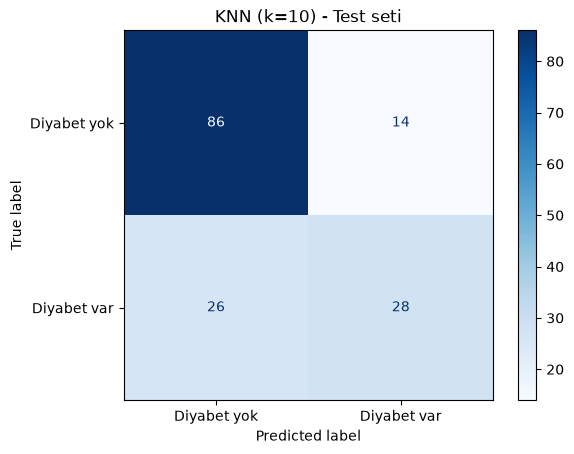

In [29]:
best = search.best_estimator_
y_pred = best.predict(X_test)

print("Test doğruluğu:", round(accuracy_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=["Diyabet yok", "Diyabet var"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Diyabet yok", "Diyabet var"],
    cmap="Blues",
)
plt.title(f"KNN (k={k}) - Test seti")
plt.show()

### best_estimator_: en iyi model (scaler + KNN, en iyi k ile).
### predict(X_test): hiç görmediği 154 kişi için tahmin yapar.
### accuracy_score: doğru tahmin oranı.
### classification_report: her sınıf için precision, recall ve f1. target_names: 0/1 yerine okunaklı isimler.
### ConfusionMatrixDisplay: doğru/yanlış tahmin matrisini çizer. cmap="Blues": mavi tonları.
### ÖZET: Modeli ilk kez test setinde denedik ve sonuçlarını tablo ve grafikle gösterdik.

KNN recall: 0.519
RF  recall: 0.741

              precision    recall  f1-score   support

 Diyabet yok       0.84      0.75      0.79       100
 Diyabet var       0.62      0.74      0.67        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.73       154
weighted avg       0.76      0.75      0.75       154



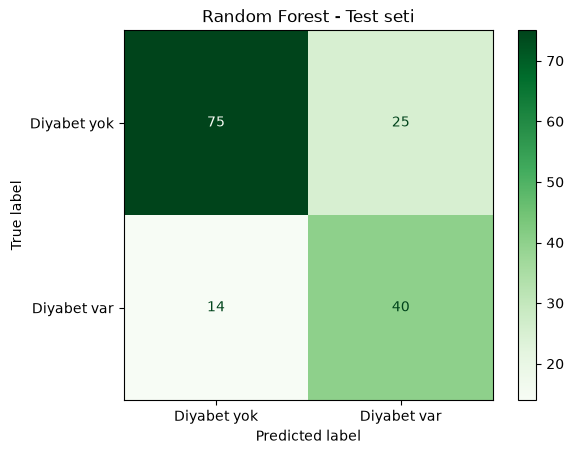

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    min_samples_leaf=5,
    random_state=42,
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("KNN recall:", round(recall_score(y_test, y_pred), 3))
print("RF  recall:", round(recall_score(y_test, y_pred_rf), 3))
print()
print(classification_report(y_test, y_pred_rf, target_names=["Diyabet yok", "Diyabet var"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=["Diyabet yok", "Diyabet var"],
    cmap="Greens",
)
plt.title("Random Forest - Test seti")
plt.show()

### RandomForestClassifier: çok sayıda karar ağacı eğitir, sonuçları oylamayla birleştirir.
###   n_estimators=300: 300 ağaç (300 hakem). Arttıkça sonuç daha kararlı olur ama yavaşlar.
###   class_weight="balanced": az olan sınıfa (diyabet) daha çok ağırlık verir, recall'u artırır.
###   min_samples_leaf=5: her yaprakta en az 5 kişi olsun. Ağaçların tek tek kişileri ezberlemesini engeller (overfitting'e karşı).
###   random_state=42: rastgeleliği sabitler, sonuçlar tekrarlanabilir olur.
### Not: Random Forest ölçeklemeye ihtiyaç duymaz. Ağaçlar mesafeye değil "glucose > 140 mı?" gibi sorulara bakar. O yüzden Pipeline'a gerek yok.
### recall_score(gerçek, tahmin): diyabetlilerin ne kadarını yakaladığımız.
### ÖZET: Random Forest'ı dengeli ağırlıklarla eğittik ve recall'unu KNN ile karşılaştırdık.

In [35]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score

proba_cv = cross_val_predict(rf, X_train, y_train, cv=5, method="predict_proba")[:, 1]

for t in [0.5, 0.45, 0.4, 0.35, 0.3]:
    pred = (proba_cv >= t).astype(int)
    print(f"eşik={t}  recall={recall_score(y_train, pred):.2f}  "
          f"precision={precision_score(y_train, pred):.2f}  "
          f"accuracy={accuracy_score(y_train, pred):.2f}")

### cross_val_predict: 5-fold CV yapar. Her kişi için, o kişiyi GÖRMEYEN modelin tahminini verir. Test setine dokunmaz.
###   method="predict_proba": 0/1 yerine olasılık döndürür (örneğin 0.62 = hakemlerin %62'si "diyabet" dedi).
###   [:, 1]: iki sütun gelir (diyabet yok / var olasılığı). Sadece "diyabet var" sütununu alıyoruz.
### (proba_cv >= t): olasılık eşikten büyük veya eşitse True. .astype(int) → True/False'u 1/0'a çevirir.
### :.2f → sayıyı virgülden sonra 2 basamakla yazdırır.
### ÖZET: Farklı eşikleri sadece eğitim verisinde (CV ile) denedik ve recall/precision dengesini karşılaştırdık.

eşik=0.5  recall=0.73  precision=0.65  accuracy=0.77
eşik=0.45  recall=0.78  precision=0.63  accuracy=0.76
eşik=0.4  recall=0.79  precision=0.59  accuracy=0.74
eşik=0.35  recall=0.81  precision=0.56  accuracy=0.71
eşik=0.3  recall=0.84  precision=0.53  accuracy=0.68


               kisi  model_diyor  gercekte
aralik                                    
(-0.001, 0.2]   203         0.09      0.07
(0.2, 0.4]      128         0.29      0.24
(0.4, 0.6]      112         0.51      0.43
(0.6, 0.8]       97         0.70      0.64
(0.8, 1.0]       74         0.88      0.78


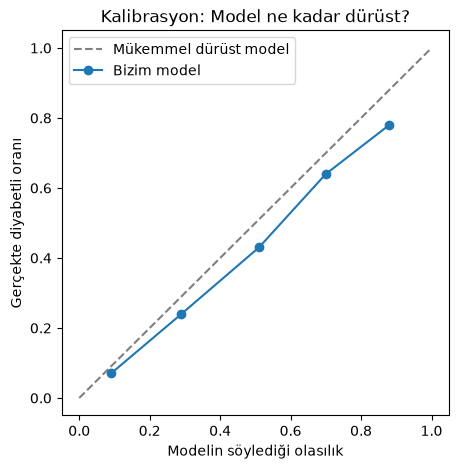

In [37]:
cal = pd.DataFrame({"olasilik": proba_cv, "gercek": y_train.values})
cal["aralik"] = pd.cut(cal["olasilik"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)

tablo = cal.groupby("aralik", observed=True).agg(
    kisi=("gercek", "size"),
    model_diyor=("olasilik", "mean"),
    gercekte=("gercek", "mean"),
).round(2)
print(tablo)

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Mükemmel dürüst model")
plt.plot(tablo["model_diyor"], tablo["gercekte"], "o-", label="Bizim model")
plt.xlabel("Modelin söylediği olasılık")
plt.ylabel("Gerçekte diyabetli oranı")
plt.title("Kalibrasyon: Model ne kadar dürüst?")
plt.legend()
plt.show()

### pd.DataFrame({...}): iki sütunlu tablo kurar. Her kişi için modelin olasılığı ve gerçek cevap (0/1).
###   y_train.values: pandas Series'ten sadece değerleri (sıra numaraları olmadan) alır.
### pd.cut(sütun, bins=[...]): sayıları aralıklara (kutulara) ayırır: 0–0.2, 0.2–0.4, ...
###   include_lowest=True: tam 0 olan değerleri de ilk kutuya dahil eder.
### groupby("aralik"): her kutu için ayrı hesap yapar. observed=True: boş kutuları göstermez.
### .agg(...): her kutu için birden fazla özet çıkarır:
###   kisi=("gercek", "size"): o kutuda kaç kişi var.
###   model_diyor=("olasilik", "mean"): model ortalama ne demiş.
###   gercekte=("gercek", "mean"): gerçekte diyabetli oranı (0/1'lerin ortalaması).
### plt.plot([0,1],[0,1], "--"): köşegen kesikli çizgi. Model dürüst olsaydı noktalar tam bu çizginin üstünde olurdu.
### "o-": noktaları yuvarlak (o) ile işaretle ve çizgiyle (-) birleştir.
### Noktalar çizginin ALTINDA kalıyorsa model abartıyor demektir.
### ÖZET: Modelin söylediği olasılıkları gerçek oranlarla karşılaştırdık. Model özellikle yüksek risklerde biraz abartıyor.

In [39]:
cal["seviye"] = pd.cut(
    cal["olasilik"],
    bins=[0, 0.3, 0.6, 1.0],
    labels=["Düşük", "Orta", "Yüksek"],
    include_lowest=True,
)

seviyeler = cal.groupby("seviye", observed=True).agg(
    kisi=("gercek", "size"),
    gercek_oran=("gercek", "mean"),
).round(2)
print(seviyeler)

### pd.cut(..., bins=[0, 0.3, 0.6, 1.0]): olasılığı 3 kutuya ayırır: 0–0.3, 0.3–0.6, 0.6–1.0.
###   labels=[...]: kutulara sayı yerine isim verir.
### gercek_oran: her seviyedeki kişilerin gerçekte ne kadarı diyabetli. Uygulamada göstereceğimiz DÜRÜST sayı bu.
###   Örneğin 0.70 → "10 kişiden yaklaşık 7'sinde diyabet vardı."
### ÖZET: Olasılıkları Düşük/Orta/Yüksek diye 3 seviyeye ayırdık ve her seviyenin gerçek diyabet oranını bulduk. Uygulamada bu oranları göstereceğiz.

        kisi  gercek_oran
seviye                   
Düşük    274         0.12
Orta     169         0.36
Yüksek   171         0.70


In [41]:
proba_test = rf.predict_proba(X_test)[:, 1]

test_cal = pd.DataFrame({"olasilik": proba_test, "gercek": y_test.values})
test_cal["seviye"] = pd.cut(
    test_cal["olasilik"],
    bins=[0, 0.3, 0.6, 1.0],
    labels=["Düşük", "Orta", "Yüksek"],
    include_lowest=True,
)

karsilastir = pd.DataFrame({
    "eğitim (CV)": seviyeler["gercek_oran"],
    "test": test_cal.groupby("seviye", observed=True)["gercek"].mean().round(2),
    "test kişi": test_cal.groupby("seviye", observed=True)["gercek"].size(),
})
print(karsilastir)

### rf.predict_proba(X_test)[:, 1]: Hücre 6'da eğittiğimiz RF ile test setindeki 154 kişinin diyabet olasılığı.
### pd.cut(...): aynı sınırlarla (0.3 ve 0.6) Düşük/Orta/Yüksek seviyelerine ayırır.
### pd.DataFrame({...}): eğitim ve test oranlarını yan yana koyan bir tablo kurar.
###   seviyeler["gercek_oran"]: Hücre 9'da eğitim verisinden bulduğumuz oranlar.
###   groupby(...)["gercek"].mean(): testte her seviyedeki gerçek diyabet oranı.
###   .size(): testte her seviyede kaç kişi olduğu.
### Eğitim ve test oranları birbirine yakınsa seviyelerimiz güvenilir demektir.
### ÖZET: Risk seviyelerini hiç görülmemiş test verisinde kontrol ettik. Oranlar eğitimdekine yakın mı diye baktık.

        eğitim (CV)  test  test kişi
seviye                              
Düşük          0.12  0.11         71
Orta           0.36  0.43         35
Yüksek         0.70  0.65         48


In [43]:
X_all = X.copy()
for col in ["glucose", "diastolic", "bmi"]:
    median = X_all.loc[X_all[col] > 0, col].median()
    X_all[col] = X_all[col].replace(0, median)

final_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    min_samples_leaf=5,
    random_state=42,
)
final_rf.fit(X_all, y)

mlmodel = ct.converters.sklearn.convert(final_rf, FEATURES, TARGET)
mlmodel.short_description = "Random Forest diyabet risk modeli (Pima veri seti)"
mlmodel.author = "Taha Serif Aydin"
mlmodel.save("../DiabetesRisk/DiabetesRisk/DiabetesRF.mlmodel")

print("Kaydedildi! Çıktılar:", [o.name for o in mlmodel.get_spec().description.output])

### X_all: tüm veri (768 kişi). Test bitti, artık final model için verinin tamamını kullanabiliriz (senin fikrin 😉).
### 0'ları yine medyanla dolduruyoruz, bu sefer tüm verinin medyanıyla.
### final_rf: Hücre 6'daki ayarların aynısı, ama 614 yerine 768 kişiyle eğitiliyor.
### ct.converters.sklearn.convert(model, girdi_isimleri, çıktı_ismi): scikit-learn modelini Core ML formatına çevirir.
###   FEATURES: iPhone'da modele verilecek 5 girdinin isimleri.
###   TARGET: tahmin çıktısının adı ("diabetes").
### short_description / author: Xcode'da modele tıklayınca görünen bilgiler.
### .save("../DiabetesRisk/..."): ".." bir üst klasör demek. Modeli iOS projesinin klasörüne kaydeder.
### Çıktılar: "diabetes" (0/1 tahmini) ve "classProbability" (olasılıklar). Uygulamada olasılığı kullanıp seviyeye çevireceğiz.
### ÖZET: En iyi ayarlarla final modeli tüm veriyle eğittik ve iPhone'un okuyabileceği DiabetesRF.mlmodel dosyasına kaydettik.

Kaydedildi! Çıktılar: ['diabetes', 'classProbability']
